# RQ3: training data and exposure — final results

E7 sampling, E8 corpus eligibility and E9 episode size address distinct changes in data exposure. E8/E9 are PD-only. The exact large-table 8,192-row control is reused once. Equal optimizer updates do not imply equal compute or unique rows. Final evaluation averages five paired outer folds within table, then weights tables equally. AUC/R² gains are CPT minus original; Brier/RMSE gains reverse direction. RMSE gains here are relative percentages.

## 0. Evidence and interpretation

The selected local evidence is a snapshot. Missing evidence remains unavailable; queued VSC jobs are not completed results.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, questions as rq, synthesis as sy, research_views as rv
from src.visualize import choice_effects as ce, comparisons as cmp, publication as pub, dashboards as db
from src.visualize import diagnostics as dg
from src.visualize import training_summary as ts, pilots as pv, finishing as finish, prediction_diagnostics as pred
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
sink = FigureSaver('rq3/02_results')
report = cp.NotebookReport('RQ3: training data and exposure — final results', sink=sink)
print(source_description())
report.add('0. Evidence and interpretation', source_description() + '\n' + 'E7 sampling, E8 corpus eligibility and E9 episode size address distinct changes in data exposure. E8/E9 are PD-only. The exact large-table 8,192-row control is reused once. Equal optimizer updates do not imply equal compute or unique rows. Final evaluation averages five paired outer folds within table, then weights tables equally. AUC/R² gains are CPT minus original; Brier/RMSE gains reverse direction. RMSE gains here are relative percentages.')

DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Coverage, protocols and unique evidence

Training completion and benchmark completion are separate. All results retain their own matched original checkpoint. The current inference-policy table governs cross-study TabICL comparisons; a pending FP32 refresh is not published evidence.

In [2]:
QUESTION = 3
studies = {track: rq.load(QUESTION, track) for track in ('pd', 'lgd')}
catalogs = {}
for track, values in studies.items():
    report.table(track.upper() + ' unique trial inventory', rv.inventory_summary(rv.unique_training_inventory(values)))
    report.table(track.upper() + ' recipe and inference comparability', sy.comparability_table(values))
    for e, arm, run in values:
        report.table(track.upper() + ' ' + str(run.cfg.run_name) + ' ' + str(arm or '') + ' five-fold coverage', cmp.benchmark_coverage(run))
    catalogs[track] = {(domain, metric): rq.catalog(values, QUESTION, metric, domain, reference_only=QUESTION == 2)
                       for domain in ('credit', 'ood') for metric in (sy.PRIMARY[track], sy.SECONDARY[track])}
report.add('1. Coverage, protocols and unique evidence', 'Training completion and benchmark completion are separate. All results retain their own matched original checkpoint. The current inference-policy table governs cross-study TabICL comparisons; a pending FP32 refresh is not published evidence.')

C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


...

,domain,base,planned_checkpoints,completed_checkpoints,paired_five_fold_comparisons,paired_datasets
0,credit,TabICLv2,4,4,17,17
1,credit,TabPFN v3,4,4,17,17
2,ood,TabICLv2,4,4,16,4
3,ood,TabPFN v3,4,4,16,4


,domain,base,planned_checkpoints,completed_checkpoints,paired_five_fold_comparisons,paired_datasets
0,credit,TabICLv2,4,4,17,17
1,credit,TabPFN v3,4,4,17,17
2,ood,TabICLv2,4,4,16,4
3,ood,TabPFN v3,4,4,16,4


,public_studies,campaign,base,status,unique_trials
0,7,cpt_sampling_v5,TabICLv2,OK,12
1,7,cpt_sampling_v5,TabPFN v2,OK,12
2,7,cpt_sampling_v5,TabPFN v2.6,OK,12
3,7,cpt_sampling_v5,TabPFN v3,OK,12


,experiments,study,campaign,arm,bases,learning_rates,l2sp,pd_sampling,training_amp,tabicl_inference,episode_rows,seed,trials
0,7,Sampling,cpt_sampling_v5,,"TabICLv2, TabPFN v2, TabPFN v2.6, TabPFN v3",3e-07,0.003,uniform rows,True,automatic,measured cap,42,48


,domain,base,planned_checkpoints,completed_checkpoints,paired_five_fold_comparisons,paired_datasets
0,credit,TabICLv2,12,12,24,8
1,credit,TabPFN v2,12,12,24,8
2,credit,TabPFN v2.6,12,12,24,8
3,credit,TabPFN v3,12,12,24,8
4,ood,TabICLv2,12,12,48,4
5,ood,TabPFN v2,12,12,48,4
6,ood,TabPFN v2.6,12,12,48,4
7,ood,TabPFN v3,12,12,48,4


## 2. Original-to-CPT effects across the research question

Different experiments are shown in one view for each metric. Every dot is a table, the diamond is the equal-table mean and the segment is the table IQR. The same tables contribute to every available arm within each model. This is heterogeneity, not a confidence interval.

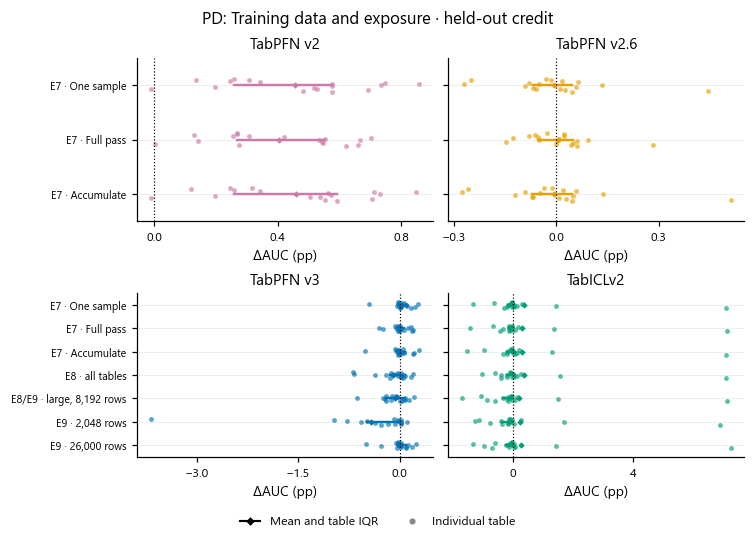

PD. Training data and exposure · held-out credit. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,3,Sampling,Full CPT,E7 Accumulate,TabICLv2,roc_auc,17,0.791790,0.794912,0.003122,...,-0.001788,0.000550,-0.015335,0.070902,4,7,6,29,85,0.235294
1,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2,roc_auc,17,0.778915,0.783491,0.004576,...,0.002584,0.005908,-0.000123,0.008476,16,1,0,78,85,0.941176
2,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2.6,roc_auc,17,0.792242,0.792164,-0.000077,...,-0.000712,0.000456,-0.002775,0.005121,2,12,3,31,85,0.117647
3,3,Sampling,Full CPT,E7 Accumulate,TabPFN v3,roc_auc,17,0.798171,0.798198,0.000027,...,-0.000341,0.000612,-0.005110,0.002899,3,13,1,35,85,0.176471
4,3,Sampling,Full CPT,E7 Full pass,TabICLv2,roc_auc,17,0.791790,0.794782,0.002991,...,-0.001452,-0.000382,-0.014243,0.070995,3,6,8,29,85,0.176471
5,3,Sampling,Full CPT,E7 Full pass,TabPFN v2,roc_auc,17,0.778915,0.782963,0.004048,...,0.002678,0.005529,0.000007,0.007011,16,1,0,79,85,0.941176
6,3,Sampling,Full CPT,E7 Full pass,TabPFN v2.6,roc_auc,17,0.792242,0.792291,0.000049,...,-0.000548,0.000490,-0.001492,0.002830,1,14,2,38,85,0.058824
7,3,Sampling,Full CPT,E7 Full pass,TabPFN v3,roc_auc,17,0.798171,0.798128,-0.000043,...,-0.000313,0.000664,-0.003085,0.001883,4,11,2,34,85,0.235294
8,3,Sampling,Full CPT,E7 One sample,TabICLv2,roc_auc,17,0.791790,0.795393,0.003603,...,-0.001660,0.000391,-0.013268,0.070909,4,7,6,36,85,0.235294
9,3,Sampling,Full CPT,E7 One sample,TabPFN v2,roc_auc,17,0.778915,0.783477,0.004563,...,0.002569,0.005761,-0.000105,0.008591,16,1,0,78,85,0.941176


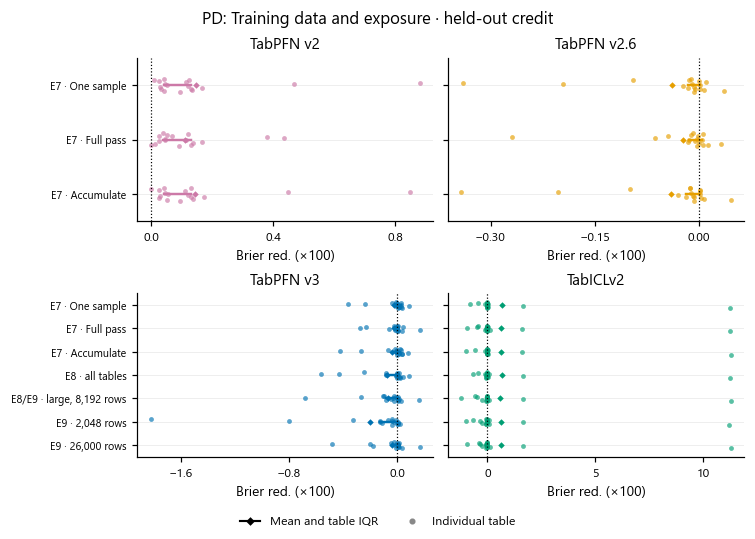

PD. Training data and exposure · held-out credit. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,3,Sampling,Full CPT,E7 Accumulate,TabICLv2,brier_score,17,0.120268,0.113720,0.006548,...,-0.000311,0.000029,-0.009884,0.112919,4,5,8,28,85,0.235294
1,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2,brier_score,17,0.118123,0.116673,0.001450,...,0.000436,0.001309,-0.000020,0.008482,16,1,0,75,85,0.941176
2,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2.6,brier_score,17,0.113695,0.114104,-0.000409,...,-0.000182,0.000009,-0.003419,0.000457,1,8,8,18,85,0.058824
3,3,Sampling,Full CPT,E7 Accumulate,TabPFN v3,brier_score,17,0.111857,0.112203,-0.000345,...,-0.000096,0.000216,-0.004258,0.000770,7,6,4,45,85,0.411765
4,3,Sampling,Full CPT,E7 Full pass,TabICLv2,brier_score,17,0.120268,0.113885,0.006383,...,-0.000579,0.000043,-0.009607,0.112812,4,2,11,26,85,0.235294
5,3,Sampling,Full CPT,E7 Full pass,TabPFN v2,brier_score,17,0.118123,0.117013,0.001110,...,0.000390,0.001290,-0.000007,0.004345,16,1,0,76,85,0.941176
6,3,Sampling,Full CPT,E7 Full pass,TabPFN v2.6,brier_score,17,0.113695,0.113920,-0.000225,...,-0.000152,0.000043,-0.002692,0.000314,2,9,6,28,85,0.117647
7,3,Sampling,Full CPT,E7 Full pass,TabPFN v3,brier_score,17,0.111857,0.112059,-0.000202,...,-0.000171,0.000091,-0.002772,0.001668,4,8,5,33,85,0.235294
8,3,Sampling,Full CPT,E7 One sample,TabICLv2,brier_score,17,0.120268,0.113531,0.006737,...,-0.000249,0.000053,-0.008277,0.112859,3,5,9,30,85,0.176471
9,3,Sampling,Full CPT,E7 One sample,TabPFN v2,brier_score,17,0.118123,0.116643,0.001481,...,0.000424,0.001300,0.000106,0.008810,17,0,0,76,85,1.000000


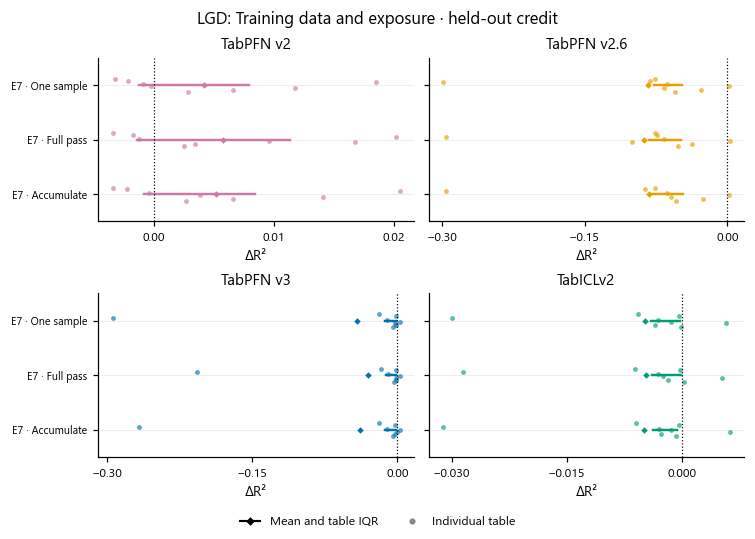

LGD. Training data and exposure · held-out credit. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,3,Sampling,Full CPT,E7 Accumulate,TabICLv2,r2,8,0.531893,0.527030,-0.004864,...,-0.003717,-0.000635,-0.031154,0.006318,1,2,5,13,40,0.125
1,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2,r2,8,0.474518,0.479739,0.005221,...,-0.000814,0.008464,-0.003379,0.020501,5,1,2,20,40,0.625
2,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2.6,r2,8,0.539808,0.457510,-0.082298,...,-0.078704,-0.046612,-0.295467,0.001362,1,0,7,5,40,0.125
3,3,Sampling,Full CPT,E7 Accumulate,TabPFN v3,r2,8,0.539412,0.501293,-0.038119,...,-0.013063,-0.001859,-0.266361,0.002257,1,1,6,10,40,0.125
4,3,Sampling,Full CPT,E7 Full pass,TabICLv2,r2,8,0.531893,0.527296,-0.004598,...,-0.003852,-0.000132,-0.028588,0.005232,1,2,5,12,40,0.125
5,3,Sampling,Full CPT,E7 Full pass,TabPFN v2,r2,8,0.474518,0.480283,0.005765,...,-0.001357,0.011377,-0.003422,0.020232,5,0,3,22,40,0.625
6,3,Sampling,Full CPT,E7 Full pass,TabPFN v2.6,r2,8,0.539808,0.452560,-0.087248,...,-0.081966,-0.048160,-0.295411,0.002776,1,0,7,5,40,0.125
7,3,Sampling,Full CPT,E7 Full pass,TabPFN v3,r2,8,0.539412,0.509361,-0.030051,...,-0.011570,-0.001781,-0.207073,0.002290,1,0,7,11,40,0.125
8,3,Sampling,Full CPT,E7 One sample,TabICLv2,r2,8,0.531893,0.527141,-0.004752,...,-0.004043,-0.000237,-0.029958,0.005813,1,2,5,13,40,0.125
9,3,Sampling,Full CPT,E7 One sample,TabPFN v2,r2,8,0.474518,0.478703,0.004185,...,-0.001188,0.007927,-0.003197,0.018570,4,2,2,21,40,0.500


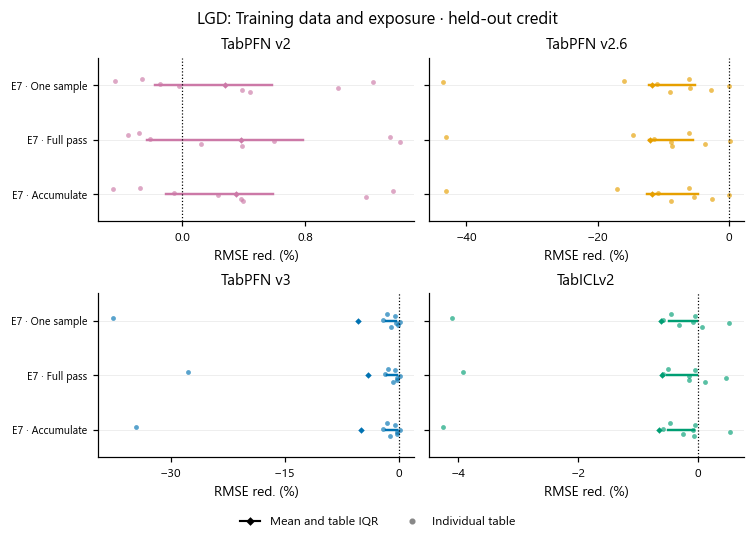

LGD. Training data and exposure · held-out credit. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,3,Sampling,Full CPT,E7 Accumulate,TabICLv2,rmse,8,0.224880,0.226414,-0.006584,...,-0.005049,-0.000709,-0.042568,0.005279,1,3,4,13,40,0.125
1,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2,rmse,8,0.240824,0.239580,0.003482,...,-0.001077,0.005922,-0.004527,0.013666,5,1,2,20,40,0.625
2,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2.6,rmse,8,0.221788,0.244471,-0.117337,...,-0.124062,-0.046545,-0.431595,0.000738,0,1,7,5,40,0.000
3,3,Sampling,Full CPT,E7 Accumulate,TabPFN v3,rmse,8,0.222704,0.234195,-0.050106,...,-0.017160,-0.002063,-0.345642,0.001358,1,0,7,10,40,0.125
4,3,Sampling,Full CPT,E7 Full pass,TabICLv2,rmse,8,0.224880,0.226302,-0.006007,...,-0.005221,-0.000134,-0.039198,0.004667,2,1,5,12,40,0.250
5,3,Sampling,Full CPT,E7 Full pass,TabPFN v2,rmse,8,0.240824,0.239489,0.003793,...,-0.002260,0.007849,-0.003512,0.014130,5,0,3,22,40,0.625
6,3,Sampling,Full CPT,E7 Full pass,TabPFN v2.6,rmse,8,0.221788,0.245720,-0.120423,...,-0.122068,-0.054878,-0.431525,0.001609,1,0,7,5,40,0.125
7,3,Sampling,Full CPT,E7 Full pass,TabPFN v3,rmse,8,0.222704,0.231985,-0.040539,...,-0.015480,-0.002048,-0.276870,0.001379,1,0,7,11,40,0.125
8,3,Sampling,Full CPT,E7 One sample,TabICLv2,rmse,8,0.224880,0.226373,-0.006299,...,-0.004881,-0.000288,-0.041019,0.005086,1,3,4,13,40,0.125
9,3,Sampling,Full CPT,E7 One sample,TabPFN v2,rmse,8,0.240824,0.239802,0.002774,...,-0.001739,0.005842,-0.004372,0.012374,4,1,3,21,40,0.500


In [3]:
for track in studies:
    for metric in (sy.PRIMARY[track], sy.SECONDARY[track]):
        data = catalogs[track]['credit', metric]
        cp.show(sink, rq.plot_effects(data, track, title=rq.TITLES[QUESTION] + ' · held-out credit', name='credit_' + metric), track=track)
        report.table(track.upper() + ' original/CPT scores and paired effects: ' + metric, sy.summarize(data))
report.add('2. Original-to-CPT effects across the research question', 'Different experiments are shown in one view for each metric. Every dot is a table, the diamond is the equal-table mean and the segment is the table IQR. The same tables contribute to every available arm within each model. This is heterogeneity, not a confidence interval.')

## 3. What changes when a specific choice changes?

Paired contrasts compare the same table and model. A positive contrast can mean less damage, not positive transfer. E7 compares sampling with one sample, E8 compares large with all tables, and E9 uses the exact shared 8,192-row control.

,base,dataset,metric,domain,effect_reference,effect_alternative,effect,config
0,TabICLv2,Bondora Peer-to-Peer,roc_auc,credit,-3.932738e-04,-0.001341,-0.000947,E7 full pass − one sample
1,TabICLv2,Cobranded,roc_auc,credit,-1.526130e-04,-0.000382,-0.000230,E7 full pass − one sample
2,TabICLv2,Credit Risk,roc_auc,credit,-6.251673e-03,-0.006684,-0.000432,E7 full pass − one sample
3,TabICLv2,GMSC,roc_auc,credit,-6.201196e-04,-0.000448,0.000172,E7 full pass − one sample
4,TabICLv2,German Credit,roc_auc,credit,2.939705e-03,0.001658,-0.001282,E7 full pass − one sample
...,...,...,...,...,...,...,...,...
233,TabPFN v3,PropPD2,roc_auc,credit,1.323866e-03,0.001844,0.000520,"E9 upper row cap − 8,192"
234,TabPFN v3,SBA Loans Case,roc_auc,credit,8.138318e-04,0.000844,0.000031,"E9 upper row cap − 8,192"
235,TabPFN v3,Taiwan Credit Card,roc_auc,credit,-8.678990e-07,0.000106,0.000107,"E9 upper row cap − 8,192"
236,TabPFN v3,Thomas,roc_auc,credit,3.174730e-04,0.000953,0.000636,"E9 upper row cap − 8,192"


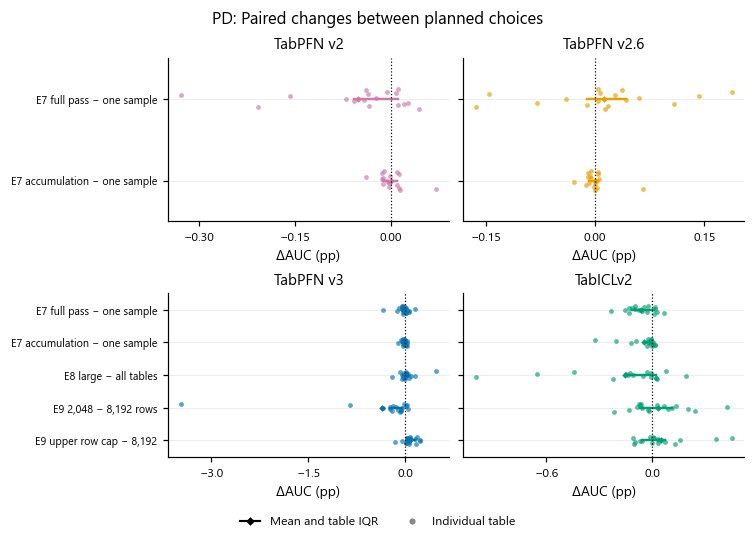

PD. Paired changes between planned choices. Paired differences between the named choices' CPT effects, on identical tables. Positive favors the alternative choice and can mean less degradation, rather than positive transfer. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Both choices' effects and their named-table differences are retained in the text summary.

,base,dataset,metric,domain,effect_reference,effect_alternative,effect,config
0,TabICLv2,Bondora Peer-to-Peer,brier_score,credit,-0.000038,-0.000380,-0.000342,E7 full pass − one sample
1,TabICLv2,Cobranded,brier_score,credit,-0.000244,-0.000315,-0.000070,E7 full pass − one sample
2,TabICLv2,Credit Risk,brier_score,credit,-0.004537,-0.004372,0.000165,E7 full pass − one sample
3,TabICLv2,GMSC,brier_score,credit,-0.000075,-0.000041,0.000034,E7 full pass − one sample
4,TabICLv2,German Credit,brier_score,credit,0.000493,0.000100,-0.000393,E7 full pass − one sample
...,...,...,...,...,...,...,...,...
233,TabPFN v3,PropPD2,brier_score,credit,0.000055,0.000066,0.000010,"E9 upper row cap − 8,192"
234,TabPFN v3,SBA Loans Case,brier_score,credit,0.001643,0.001688,0.000045,"E9 upper row cap − 8,192"
235,TabPFN v3,Taiwan Credit Card,brier_score,credit,0.000086,0.000136,0.000050,"E9 upper row cap − 8,192"
236,TabPFN v3,Thomas,brier_score,credit,0.000270,0.000391,0.000121,"E9 upper row cap − 8,192"


,base,dataset,metric,domain,effect_reference,effect_alternative,effect,config
0,TabICLv2,Freddie Mac,r2,credit,-0.005623,-0.006133,-0.000511,E7 full pass − one sample
1,TabICLv2,LendingClub (LGD),r2,credit,-0.000306,-0.000264,0.000042,E7 full pass − one sample
2,TabICLv2,PropLGD1,r2,credit,-0.029958,-0.028588,0.001370,E7 full pass − one sample
3,TabICLv2,PropLGD2,r2,credit,-0.003033,-0.003092,-0.000059,E7 full pass − one sample
4,TabICLv2,PropLGD3,r2,credit,-0.001364,-0.002481,-0.001117,E7 full pass − one sample
...,...,...,...,...,...,...,...,...
59,TabPFN v3,PropLGD2,r2,credit,-0.011092,-0.011062,0.000031,E7 accumulation − one sample
60,TabPFN v3,PropLGD3,r2,credit,0.002205,0.002257,0.000052,E7 accumulation − one sample
61,TabPFN v3,PropLGD4,r2,credit,-0.002556,-0.000952,0.001604,E7 accumulation − one sample
62,TabPFN v3,PropLGD5,r2,credit,-0.001388,-0.002653,-0.001264,E7 accumulation − one sample


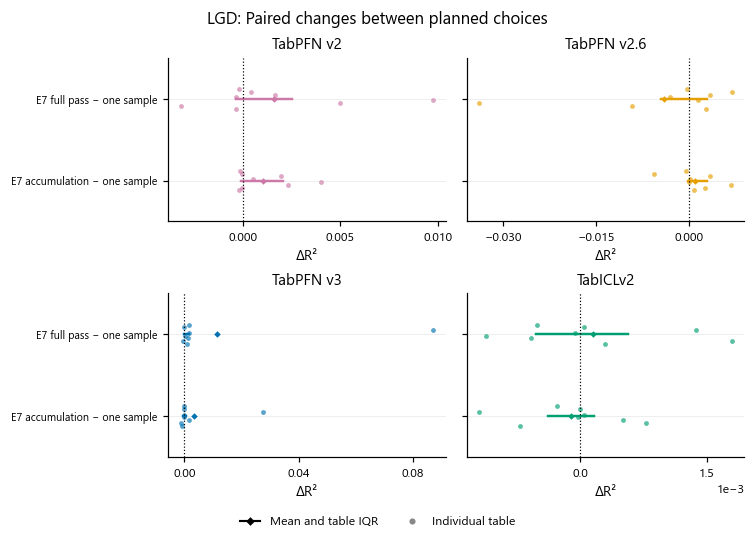

LGD. Paired changes between planned choices. Paired differences between the named choices' CPT effects, on identical tables. Positive favors the alternative choice and can mean less degradation, rather than positive transfer. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Both choices' effects and their named-table differences are retained in the text summary.

,base,dataset,metric,domain,effect_reference,effect_alternative,effect,config
0,TabICLv2,Freddie Mac,rmse,credit,-0.004570,-0.004984,-0.000414,E7 full pass − one sample
1,TabICLv2,LendingClub (LGD),rmse,credit,-0.000595,-0.000531,0.000065,E7 full pass − one sample
2,TabICLv2,PropLGD1,rmse,credit,-0.041019,-0.039198,0.001821,E7 full pass − one sample
3,TabICLv2,PropLGD2,rmse,credit,-0.005814,-0.005932,-0.000119,E7 full pass − one sample
4,TabICLv2,PropLGD3,rmse,credit,-0.000846,-0.001559,-0.000713,E7 full pass − one sample
...,...,...,...,...,...,...,...,...
59,TabPFN v3,PropLGD2,rmse,credit,-0.021005,-0.020981,0.000024,E7 accumulation − one sample
60,TabPFN v3,PropLGD3,rmse,credit,0.001325,0.001358,0.000034,E7 accumulation − one sample
61,TabPFN v3,PropLGD4,rmse,credit,-0.003405,-0.002016,0.001389,E7 accumulation − one sample
62,TabPFN v3,PropLGD5,rmse,credit,-0.000967,-0.002079,-0.001112,E7 accumulation − one sample


In [4]:
for track in studies:
    for metric in (sy.PRIMARY[track], sy.SECONDARY[track]):
        differences = rq.choice_differences(catalogs[track]['credit', metric], QUESTION)
        report.table(track.upper() + ' matched choice differences: ' + metric, differences)
        if metric == sy.PRIMARY[track]:
            cp.show(sink, rq.plot_effects(differences, track, title='Paired changes between planned choices', name='choices_' + metric, contrast=True), track=track)
report.add('3. What changes when a specific choice changes?', 'Paired contrasts compare the same table and model. A positive contrast can mean less damage, not positive transfer. E7 compares sampling with one sample, E8 compares large with all tables, and E9 uses the exact shared 8,192-row control.')

## 4. Non-credit retention alongside transfer

The four same-task non-credit tables are a bounded retention panel. Their four training-partition results are averaged within table before equal-table summaries. Original/CPT comparisons remain paired within each recipe and precision policy.

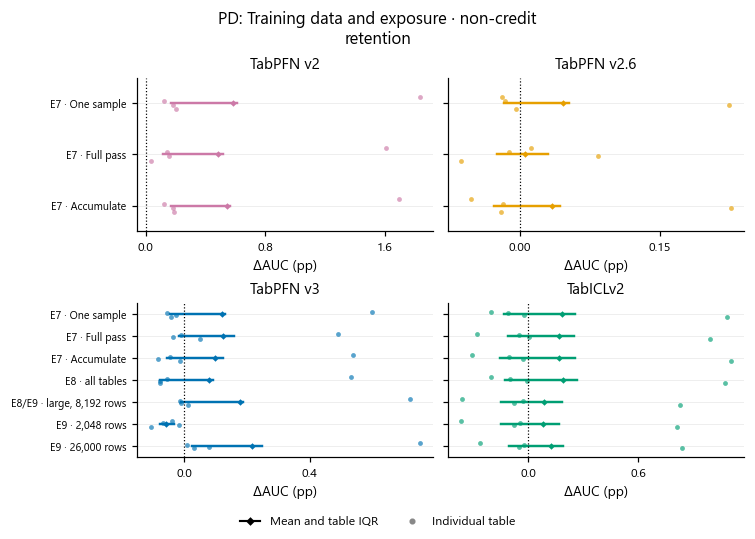

PD. Training data and exposure · non-credit retention. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,3,Sampling,Full CPT,E7 Accumulate,TabICLv2,roc_auc,4,0.872510,0.874159,0.001649,...,-0.001566,0.002534,-0.003104,0.011064,1,1,2,37,80,0.25
1,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2,roc_auc,4,0.848628,0.854091,0.005463,...,0.001678,0.005637,0.001218,0.016933,4,0,0,69,80,1.00
2,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2.6,roc_auc,4,0.871975,0.872318,0.000343,...,-0.000279,0.000436,-0.000516,0.002259,1,3,0,47,80,0.25
3,3,Sampling,Full CPT,E7 Accumulate,TabPFN v3,roc_auc,4,0.872980,0.873972,0.000992,...,-0.000541,0.001249,-0.000831,0.005365,1,3,0,41,80,0.25
4,3,Sampling,Full CPT,E7 Full pass,TabICLv2,roc_auc,4,0.872510,0.874158,0.001648,...,-0.001087,0.002497,-0.002835,0.009903,1,2,1,39,80,0.25
5,3,Sampling,Full CPT,E7 Full pass,TabPFN v2,roc_auc,4,0.848628,0.853473,0.004845,...,0.001145,0.005181,0.000328,0.016093,3,1,0,64,80,0.75
6,3,Sampling,Full CPT,E7 Full pass,TabPFN v2.6,roc_auc,4,0.871975,0.872032,0.000056,...,-0.000243,0.000304,-0.000622,0.000838,0,4,0,39,80,0.00
7,3,Sampling,Full CPT,E7 Full pass,TabPFN v3,roc_auc,4,0.872980,0.874212,0.001232,...,-0.000169,0.001600,-0.000369,0.004899,1,3,0,42,80,0.25
8,3,Sampling,Full CPT,E7 One sample,TabICLv2,roc_auc,4,0.872510,0.874370,0.001860,...,-0.001341,0.002528,-0.002041,0.010829,1,1,2,39,80,0.25
9,3,Sampling,Full CPT,E7 One sample,TabPFN v2,roc_auc,4,0.848628,0.854491,0.005863,...,0.001678,0.006126,0.001211,0.018360,4,0,0,72,80,1.00


,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,3,Sampling,Full CPT,E7 Accumulate,TabICLv2,brier_score,4,0.062642,0.063137,-0.000496,...,-0.000980,-0.000051,-0.001295,0.000382,1,0,3,28,80,0.25
1,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2,brier_score,4,0.066848,0.065702,0.001145,...,0.000529,0.001485,0.000332,0.002512,4,0,0,71,80,1.00
2,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2.6,brier_score,4,0.064141,0.063715,0.000427,...,-0.000034,0.000463,-0.000091,0.001794,1,3,0,43,80,0.25
3,3,Sampling,Full CPT,E7 Accumulate,TabPFN v3,brier_score,4,0.062912,0.063212,-0.000301,...,-0.000467,0.000064,-0.001135,0.000137,1,1,2,36,80,0.25
4,3,Sampling,Full CPT,E7 Full pass,TabICLv2,brier_score,4,0.062642,0.062920,-0.000278,...,-0.000501,0.000015,-0.000993,0.000296,1,1,2,28,80,0.25
5,3,Sampling,Full CPT,E7 Full pass,TabPFN v2,brier_score,4,0.066848,0.065973,0.000875,...,0.000572,0.000968,0.000298,0.001873,4,0,0,66,80,1.00
6,3,Sampling,Full CPT,E7 Full pass,TabPFN v2.6,brier_score,4,0.064141,0.063933,0.000208,...,-0.000048,0.000229,-0.000075,0.000963,1,3,0,45,80,0.25
7,3,Sampling,Full CPT,E7 Full pass,TabPFN v3,brier_score,4,0.062912,0.063114,-0.000202,...,-0.000254,-0.000071,-0.000622,0.000061,0,1,3,31,80,0.00
8,3,Sampling,Full CPT,E7 One sample,TabICLv2,brier_score,4,0.062642,0.063056,-0.000415,...,-0.000850,-0.000086,-0.000985,0.000368,1,0,3,28,80,0.25
9,3,Sampling,Full CPT,E7 One sample,TabPFN v2,brier_score,4,0.066848,0.065663,0.001185,...,0.000534,0.001529,0.000339,0.002646,4,0,0,71,80,1.00


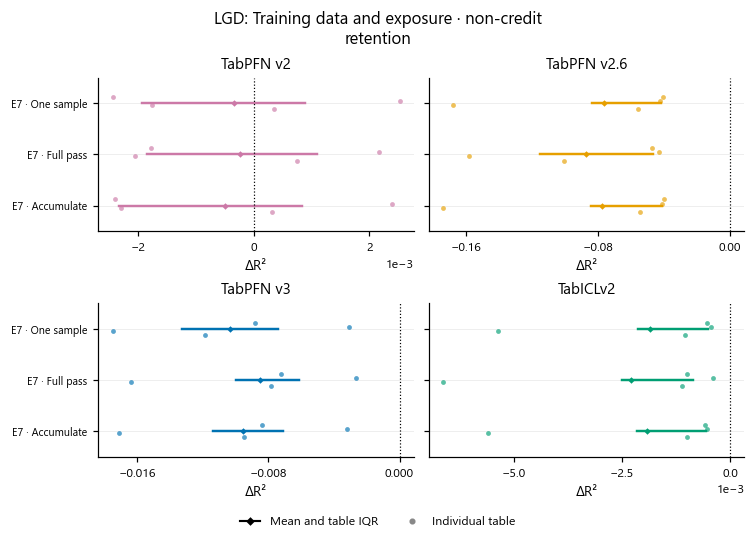

LGD. Training data and exposure · non-credit retention. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,3,Sampling,Full CPT,E7 Accumulate,TabICLv2,r2,4,0.904612,0.902689,-0.001923,...,-0.002151,-0.000558,-0.005599,-0.000524,0,2,2,13,80,0.00
1,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2,r2,4,0.876377,0.875878,-0.000498,...,-0.002323,0.000833,-0.002393,0.002382,1,1,2,35,80,0.25
2,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2.6,r2,4,0.900482,0.823069,-0.077413,...,-0.084187,-0.041013,-0.173821,-0.040259,0,0,4,0,80,0.00
3,3,Sampling,Full CPT,E7 Accumulate,TabPFN v3,r2,4,0.908109,0.898560,-0.009549,...,-0.011395,-0.007082,-0.017118,-0.003224,0,0,4,0,80,0.00
4,3,Sampling,Full CPT,E7 Full pass,TabICLv2,r2,4,0.904612,0.902325,-0.002287,...,-0.002494,-0.000848,-0.006638,-0.000401,0,2,2,12,80,0.00
5,3,Sampling,Full CPT,E7 Full pass,TabPFN v2,r2,4,0.876377,0.876146,-0.000231,...,-0.001844,0.001098,-0.002055,0.002162,1,1,2,38,80,0.25
6,3,Sampling,Full CPT,E7 Full pass,TabPFN v2.6,r2,4,0.900482,0.813120,-0.087362,...,-0.115004,-0.046351,-0.158218,-0.043245,0,0,4,0,80,0.00
7,3,Sampling,Full CPT,E7 Full pass,TabPFN v3,r2,4,0.908109,0.899567,-0.008542,...,-0.009970,-0.006113,-0.016412,-0.002671,0,0,4,0,80,0.00
8,3,Sampling,Full CPT,E7 One sample,TabICLv2,r2,4,0.904612,0.902765,-0.001847,...,-0.002120,-0.000514,-0.005371,-0.000444,0,2,2,14,80,0.00
9,3,Sampling,Full CPT,E7 One sample,TabPFN v2,r2,4,0.876377,0.876042,-0.000335,...,-0.001934,0.000888,-0.002440,0.002520,1,1,2,34,80,0.25


,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,3,Sampling,Full CPT,E7 Accumulate,TabICLv2,rmse,4,4.209601,4.242711,-0.009021,...,-0.011224,-0.006922,-0.011850,-0.005984,0,0,4,13,80,0.0
1,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2,rmse,4,4.617752,4.606774,-0.004738,...,-0.012307,0.006753,-0.038596,0.021277,2,0,2,35,80,0.5
2,3,Sampling,Full CPT,E7 Accumulate,TabPFN v2.6,rmse,4,4.307522,5.764401,-0.388669,...,-0.404438,-0.317179,-0.581383,-0.307398,0,0,4,0,80,0.0
3,3,Sampling,Full CPT,E7 Accumulate,TabPFN v3,rmse,4,4.182410,4.431593,-0.080370,...,-0.095337,-0.036315,-0.185799,-0.033119,0,0,4,0,80,0.0
4,3,Sampling,Full CPT,E7 Full pass,TabICLv2,rmse,4,4.209601,4.247153,-0.011428,...,-0.015210,-0.007255,-0.018743,-0.004893,0,0,4,12,80,0.0
5,3,Sampling,Full CPT,E7 Full pass,TabPFN v2,rmse,4,4.617752,4.599049,-0.001996,...,-0.009517,0.008186,-0.028552,0.019239,2,0,2,38,80,0.5
6,3,Sampling,Full CPT,E7 Full pass,TabPFN v2.6,rmse,4,4.307522,6.279796,-0.458722,...,-0.567119,-0.337952,-0.658311,-0.283878,0,0,4,0,80,0.0
7,3,Sampling,Full CPT,E7 Full pass,TabPFN v3,rmse,4,4.182410,4.394035,-0.069936,...,-0.080857,-0.033876,-0.162216,-0.027937,0,0,4,0,80,0.0
8,3,Sampling,Full CPT,E7 One sample,TabICLv2,rmse,4,4.209601,4.242044,-0.008637,...,-0.010732,-0.006900,-0.011370,-0.005189,0,0,4,14,80,0.0
9,3,Sampling,Full CPT,E7 One sample,TabPFN v2,rmse,4,4.617752,4.604648,-0.004374,...,-0.011898,0.007200,-0.039438,0.022590,2,0,2,34,80,0.5


In [5]:
for track, values in studies.items():
    primary = catalogs[track]['credit', sy.PRIMARY[track]]
    retention = catalogs[track]['ood', sy.PRIMARY[track]]
    cp.show(sink, rq.plot_effects(retention, track, title=rq.TITLES[QUESTION] + ' · non-credit retention', name='retention_' + sy.PRIMARY[track], min_arms=2 if QUESTION == 2 else 1), track=track)
    for metric in (sy.PRIMARY[track], sy.SECONDARY[track]):
        report.table(track.upper() + ' non-credit absolute scores and effects: ' + metric, sy.summarize(catalogs[track]['ood', metric]))
report.add('4. Non-credit retention alongside transfer', 'The four same-task non-credit tables are a bounded retention panel. Their four training-partition results are averaged within table before equal-table summaries. Original/CPT comparisons remain paired within each recipe and precision policy.')

## 5. Secondary outcomes and saved-prediction evidence

Calibration, log loss and regression errors retain their distinct meanings. Detailed per-table prediction summaries remain available without another repeated figure for each experiment. No post-hoc metric is used to choose the recipe.

In [6]:
for track, values in studies.items():
    for e, arm, run in values:
        if e == 1:
            continue
        label = track.upper() + ' ' + str(run.cfg.run_name) + ' ' + str(arm or '')
        for metric in (('log_loss', 'ece', 'f1') if track == 'pd' else ('mae',)):
            report.table(label + ' ' + metric, cp.benchmark_effects(run, metric))
        diagnostic, support = pred.analyze(run, arm=arm)
        report.table(label + ' prediction support', support)
        report.table(label + ' prediction diagnostics', diagnostic)
report.add('5. Secondary outcomes and saved-prediction evidence', 'Calibration, log loss and regression errors retain their distinct meanings. Detailed per-table prediction summaries remain available without another repeated figure for each experiment. No post-hoc metric is used to choose the recipe.')

,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed
0,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Bondora Peer-to-Peer,0.256286,0.256652,-0.000366,-0.000366,Bondora Peer-to-Peer,TabICLv2,3.000000e-07,False,0.003,accumulate,-0.000366,42
1,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Cobranded,0.404884,0.405977,-0.001093,-0.001093,Cobranded,TabICLv2,3.000000e-07,False,0.003,accumulate,-0.001093,42
2,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Credit Risk,0.176320,0.196745,-0.020425,-0.020425,Credit Risk,TabICLv2,3.000000e-07,False,0.003,accumulate,-0.020425,42
3,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,GMSC,0.178188,0.178882,-0.000694,-0.000694,GMSC,TabICLv2,3.000000e-07,False,0.003,accumulate,-0.000694,42
4,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,German Credit,0.496485,0.494582,0.001903,0.001903,German Credit,TabICLv2,3.000000e-07,False,0.003,accumulate,0.001903,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropPD2,0.297591,0.296902,0.000689,0.000689,PropPD2,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.000689,42
200,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,SBA Loans Case,0.119508,0.117309,0.002199,0.002199,SBA Loans Case,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.002199,42
201,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Taiwan Credit Card,0.424775,0.424234,0.000541,0.000541,Taiwan Credit Card,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.000541,42
202,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Thomas,0.550369,0.549640,0.000729,0.000729,Thomas,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.000729,42


,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed
0,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Bondora Peer-to-Peer,0.008315,0.007664,0.000651,0.000651,Bondora Peer-to-Peer,TabICLv2,3.000000e-07,False,0.003,accumulate,0.000651,42
1,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Cobranded,0.015650,0.020350,-0.004700,-0.004700,Cobranded,TabICLv2,3.000000e-07,False,0.003,accumulate,-0.004700,42
2,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Credit Risk,0.011652,0.008851,0.002800,0.002800,Credit Risk,TabICLv2,3.000000e-07,False,0.003,accumulate,0.002800,42
3,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,GMSC,0.009839,0.011090,-0.001251,-0.001251,GMSC,TabICLv2,3.000000e-07,False,0.003,accumulate,-0.001251,42
4,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,German Credit,0.047749,0.060354,-0.012605,-0.012605,German Credit,TabICLv2,3.000000e-07,False,0.003,accumulate,-0.012605,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropPD2,0.017704,0.016338,0.001367,0.001367,PropPD2,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.001367,42
200,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,SBA Loans Case,0.022170,0.023733,-0.001562,-0.001562,SBA Loans Case,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.001562,42
201,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Taiwan Credit Card,0.022960,0.020973,0.001987,0.001987,Taiwan Credit Card,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.001987,42
202,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Thomas,0.046704,0.042970,0.003734,0.003734,Thomas,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.003734,42


,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed
0,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Bondora Peer-to-Peer,0.566443,0.564995,-0.001448,-0.001448,Bondora Peer-to-Peer,TabICLv2,3.000000e-07,False,0.003,accumulate,-0.001448,42
1,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Cobranded,0.609926,0.609796,-0.000130,-0.000130,Cobranded,TabICLv2,3.000000e-07,False,0.003,accumulate,-0.000130,42
2,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Credit Risk,0.845970,0.824116,-0.021854,-0.021854,Credit Risk,TabICLv2,3.000000e-07,False,0.003,accumulate,-0.021854,42
3,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,GMSC,0.443449,0.442496,-0.000954,-0.000954,GMSC,TabICLv2,3.000000e-07,False,0.003,accumulate,-0.000954,42
4,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,German Credit,0.604051,0.590714,-0.013337,-0.013337,German Credit,TabICLv2,3.000000e-07,False,0.003,accumulate,-0.013337,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropPD2,0.230282,0.227622,-0.002661,-0.002661,PropPD2,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.002661,42
200,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,SBA Loans Case,0.923122,0.922356,-0.000765,-0.000765,SBA Loans Case,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.000765,42
201,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Taiwan Credit Card,0.548195,0.546362,-0.001833,-0.001833,Taiwan Credit Card,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.001833,42
202,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Thomas,0.432436,0.444375,0.011939,0.011939,Thomas,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.011939,42


,base,dataset,partition,arm,status,reason
0,TabICLv2,Bondora Peer-to-Peer,0,Accumulate,verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,Bondora Peer-to-Peer,0,Full pass,verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,Bondora Peer-to-Peer,0,One sample,verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,HMEQ,0,Accumulate,verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,HMEQ,0,Full pass,verified,"Five folds; matched row identities, targets an..."
...,...,...,...,...,...,...
199,TabPFN v3,LendingClub,3,Full pass,verified,"Five folds; matched row identities, targets an..."
200,TabPFN v3,LendingClub,3,One sample,verified,"Five folds; matched row identities, targets an..."
201,TabPFN v3,SBA Loans Case,3,Accumulate,verified,"Five folds; matched row identities, targets an..."
202,TabPFN v3,SBA Loans Case,3,Full pass,verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,Bondora Peer-to-Peer,0,Accumulate,730176,0.138105,0.135123,0.132045,-0.002982,-0.006060,-0.003078,0.080536,0.080653,-0.000117,-0.003078,0.021884,0.010562
1,TabICLv2,Bondora Peer-to-Peer,0,Full pass,730176,0.138105,0.135123,0.133189,-0.002982,-0.004916,-0.001934,0.080536,0.080916,-0.000380,-0.001934,0.022475,0.011012
2,TabICLv2,Bondora Peer-to-Peer,0,One sample,730176,0.138105,0.135123,0.132365,-0.002982,-0.005740,-0.002758,0.080536,0.080574,-0.000038,-0.002758,0.019842,0.009465
3,TabICLv2,HMEQ,0,Accumulate,5960,0.199497,0.190717,0.194176,-0.008779,-0.005321,0.003458,0.017686,0.018918,-0.001232,0.003458,0.039555,0.013202
4,TabICLv2,HMEQ,0,Full pass,5960,0.199497,0.190717,0.192825,-0.008779,-0.006671,0.002108,0.017686,0.022321,-0.004635,0.002108,0.050174,0.018589
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199,TabPFN v3,LendingClub,3,Full pass,9578,0.160054,0.140981,0.139871,-0.019073,-0.020184,-0.001111,0.126388,0.126389,-0.000001,-0.001111,0.007943,0.005756
200,TabPFN v3,LendingClub,3,One sample,9578,0.160054,0.140981,0.138853,-0.019073,-0.021201,-0.002128,0.126388,0.126414,-0.000025,-0.002128,0.010997,0.007908
201,TabPFN v3,SBA Loans Case,3,Accumulate,2102,0.326356,0.326395,0.326718,0.000039,0.000362,-0.000323,0.033249,0.032892,0.000357,0.000323,0.027268,0.010249
202,TabPFN v3,SBA Loans Case,3,Full pass,2102,0.326356,0.326395,0.325977,0.000039,-0.000379,-0.000340,0.033249,0.031582,0.001668,-0.000418,0.027926,0.009378


...

,base,dataset,partition,arm,status,reason
0,TabICLv2,Bondora Peer-to-Peer,0,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,HMEQ,0,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,MicroFinance,0,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,Thomas,0,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,GMSC,1,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
5,TabICLv2,German Credit,1,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
6,TabICLv2,Taiwan Credit Card,1,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
7,TabICLv2,Vehicle Loan,1,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
8,TabICLv2,Credit Risk,2,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
9,TabICLv2,Hackerearth,2,"26,000 rows",verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,Bondora Peer-to-Peer,0,"26,000 rows",730176,0.138105,0.135123,0.133214,-0.002982,-0.004891,-0.001909,0.080536,0.080609,-0.000073,-0.001909,0.019924,0.009614
1,TabICLv2,HMEQ,0,"26,000 rows",5960,0.199497,0.190717,0.194465,-0.008779,-0.005031,0.003748,0.017686,0.021260,-0.003574,0.003748,0.044608,0.015359
2,TabICLv2,MicroFinance,0,"26,000 rows",158700,0.378091,0.364956,0.363308,-0.013134,-0.014782,-0.001648,0.218164,0.218585,-0.000421,-0.001648,0.030119,0.022415
3,TabICLv2,Thomas,0,"26,000 rows",1225,0.263673,0.247090,0.243615,-0.016584,-0.020059,-0.003475,0.183083,0.183625,-0.000542,-0.003475,0.018190,0.012581
4,TabICLv2,GMSC,1,"26,000 rows",150000,0.066840,0.057865,0.056682,-0.008975,-0.010158,-0.001183,0.049076,0.049140,-0.000065,-0.001183,0.006866,0.003306
5,TabICLv2,German Credit,1,"26,000 rows",999,0.300300,0.292743,0.290877,-0.007557,-0.009423,-0.001867,0.162400,0.162818,-0.000418,-0.001867,0.028216,0.019580
6,TabICLv2,Taiwan Credit Card,1,"26,000 rows",30000,0.221200,0.206801,0.205003,-0.014399,-0.016197,-0.001797,0.132926,0.133203,-0.000277,-0.001797,0.014475,0.010397
7,TabICLv2,Vehicle Loan,1,"26,000 rows",233154,0.217071,0.387294,0.194414,0.170223,-0.022657,0.147566,0.274762,0.161721,0.113041,-0.192880,0.349053,0.216262
8,TabICLv2,Credit Risk,2,"26,000 rows",32581,0.218164,0.207034,0.210042,-0.011130,-0.008122,0.003008,0.049365,0.053114,-0.003750,0.003008,0.047709,0.022788
9,TabICLv2,Hackerearth,2,"26,000 rows",532428,0.236327,0.231125,0.223301,-0.005201,-0.013026,-0.007825,0.058127,0.067629,-0.009501,-0.007825,0.089664,0.042675


,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed
0,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Freddie Mac,0.197262,0.198868,-0.001606,-0.001606,Freddie Mac,TabICLv2,3.000000e-07,False,0.003,accumulate,-0.001606,42
1,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,LendingClub (LGD),0.063661,0.062436,0.001225,0.001225,LendingClub (LGD),TabICLv2,3.000000e-07,False,0.003,accumulate,0.001225,42
2,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,PropLGD1,0.158676,0.176021,-0.017345,-0.017345,PropLGD1,TabICLv2,3.000000e-07,False,0.003,accumulate,-0.017345,42
3,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,PropLGD2,0.098321,0.099257,-0.000936,-0.000936,PropLGD2,TabICLv2,3.000000e-07,False,0.003,accumulate,-0.000936,42
4,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,PropLGD3,0.219388,0.217629,0.001759,0.001759,PropLGD3,TabICLv2,3.000000e-07,False,0.003,accumulate,0.001759,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD2,0.096023,0.102202,-0.006178,-0.006178,PropLGD2,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.006178,42
92,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD3,0.213285,0.219781,-0.006496,-0.006496,PropLGD3,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.006496,42
93,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD4,0.205333,0.218037,-0.012704,-0.012704,PropLGD4,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.012704,42
94,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD5,0.227024,0.238382,-0.011357,-0.011357,PropLGD5,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.011357,42


,base,dataset,partition,arm,status,reason
0,TabICLv2,PropLGD2,0,Accumulate,verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,PropLGD2,0,Full pass,verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,PropLGD2,0,One sample,verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,PropLGD3,0,Accumulate,verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,PropLGD3,0,Full pass,verified,"Five folds; matched row identities, targets an..."
...,...,...,...,...,...,...
91,TabPFN v3,PropLGD4,3,Full pass,verified,"Five folds; matched row identities, targets an..."
92,TabPFN v3,PropLGD4,3,One sample,verified,"Five folds; matched row identities, targets an..."
93,TabPFN v3,SBA Loans Case (LGD),3,Accumulate,verified,"Five folds; matched row identities, targets an..."
94,TabPFN v3,SBA Loans Case (LGD),3,Full pass,verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,PropLGD2,0,Accumulate,4637,0.392032,0.389708,0.393949,-0.002324,0.001916,0.000408,0.020062,0.020285,-0.000223,0.004241,0.020118,0.013340
1,TabICLv2,PropLGD2,0,Full pass,4637,0.392032,0.389708,0.392779,-0.002324,0.000746,0.001578,0.020062,0.020292,-0.000230,0.003071,0.018023,0.012172
2,TabICLv2,PropLGD2,0,One sample,4637,0.392032,0.389708,0.393312,-0.002324,0.001279,0.001045,0.020062,0.020288,-0.000226,0.003604,0.019602,0.012996
3,TabICLv2,PropLGD3,0,Accumulate,2545,0.228130,0.233179,0.230506,0.005049,0.002376,0.002674,0.085244,0.085390,-0.000146,-0.002674,0.007354,0.005982
4,TabICLv2,PropLGD3,0,Full pass,2545,0.228130,0.233179,0.233024,0.005049,0.004894,0.000155,0.085244,0.085502,-0.000259,-0.000155,0.008435,0.005994
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,TabPFN v3,PropLGD4,3,Full pass,762,0.323387,0.321856,0.332763,-0.001531,0.009376,-0.007845,0.082259,0.082428,-0.000169,0.010907,0.037628,0.031279
92,TabPFN v3,PropLGD4,3,One sample,762,0.323387,0.321856,0.327476,-0.001531,0.004088,-0.002557,0.082259,0.082618,-0.000359,0.005620,0.040743,0.032818
93,TabPFN v3,SBA Loans Case (LGD),3,Accumulate,686,0.628030,0.632573,0.622530,0.004543,-0.005500,-0.000957,0.017543,0.017854,-0.000311,-0.010043,0.028393,0.021615
94,TabPFN v3,SBA Loans Case (LGD),3,Full pass,686,0.628030,0.632573,0.623830,0.004543,-0.004200,0.000343,0.017543,0.017755,-0.000212,-0.008743,0.026412,0.020198


## 6. Cost, complete numerical results and conclusions

Transfer is model-, task- and recipe-dependent. Compare paired changes rather than raw scores across different inference settings. Missing model additions are explicit. These empirical questions were organized after results were visible; they are not preregistered directional hypotheses.

In [7]:
for track, values in studies.items():
    primary = catalogs[track]['credit', sy.PRIMARY[track]]
    report.table(track.upper() + ' recorded cost', sy.costs(values))
    for (domain, metric), data in catalogs[track].items():
        report.table(track.upper() + ' all named-table pairs: ' + domain + ' ' + metric, data)
report.add('6. Cost, complete numerical results and conclusions', 'Transfer is model-, task- and recipe-dependent. Compare paired changes rather than raw scores across different inference settings. Missing model additions are explicit. These empirical questions were organized after results were visible; they are not preregistered directional hypotheses.')

,base,learning_rate,l2sp_lambda,frozen,sampling,experiment,arm,gpu_hours,partitions
0,TabICLv2,3.000000e-07,0.003,False,accumulate,3,None,50.807535,4
1,TabICLv2,3.000000e-07,0.003,False,full_pass,3,None,8.262733,4
2,TabICLv2,3.000000e-07,0.003,False,one_sample,3,None,6.705928,4
3,TabPFN v2,3.000000e-07,0.003,False,accumulate,3,None,101.311714,4
4,TabPFN v2,3.000000e-07,0.003,False,full_pass,3,None,7.095397,4
5,TabPFN v2,3.000000e-07,0.003,False,one_sample,3,None,5.899897,4
6,TabPFN v2.6,3.000000e-07,0.003,False,accumulate,3,None,79.024809,4
7,TabPFN v2.6,3.000000e-07,0.003,False,full_pass,3,None,5.899166,4
8,TabPFN v2.6,3.000000e-07,0.003,False,one_sample,3,None,4.921963,4
9,TabPFN v3,3.000000e-07,0.003,False,accumulate,3,None,42.804149,4


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
0,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Bondora Peer-to-Peer,0.897214,0.896600,-0.000614,5,0,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,roc_auc,credit,Accumulate,False,E7 Accumulate
1,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Cobranded,0.842771,0.842587,-0.000184,5,2,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,roc_auc,credit,Accumulate,False,E7 Accumulate
2,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Credit Risk,0.955142,0.945650,-0.009492,5,0,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,roc_auc,credit,Accumulate,False,E7 Accumulate
3,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,GMSC,0.867187,0.866494,-0.000694,5,1,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,roc_auc,credit,Accumulate,False,E7 Accumulate
4,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,German Credit,0.790140,0.792153,0.002013,5,3,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,roc_auc,credit,Accumulate,False,E7 Accumulate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
335,tabpfn-trained__v3-default__lr3e-07__min10001_...,v3-default,PropPD2,0.657269,0.659113,0.001844,5,5,1,TabPFN v3,...,one_sample,Full CPT,7,Episode size,"26,000 rows",roc_auc,credit,"26,000 rows",False,"E9 26,000 rows"
336,tabpfn-trained__v3-default__lr3e-07__min10001_...,v3-default,SBA Loans Case,0.989833,0.990677,0.000844,5,5,1,TabPFN v3,...,one_sample,Full CPT,7,Episode size,"26,000 rows",roc_auc,credit,"26,000 rows",False,"E9 26,000 rows"
337,tabpfn-trained__v3-default__lr3e-07__min10001_...,v3-default,Taiwan Credit Card,0.789665,0.789771,0.000106,5,3,1,TabPFN v3,...,one_sample,Full CPT,7,Episode size,"26,000 rows",roc_auc,credit,"26,000 rows",False,"E9 26,000 rows"
338,tabpfn-trained__v3-default__lr3e-07__min10001_...,v3-default,Thomas,0.651588,0.652541,0.000953,5,3,1,TabPFN v3,...,one_sample,Full CPT,7,Episode size,"26,000 rows",roc_auc,credit,"26,000 rows",False,"E9 26,000 rows"


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
0,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Bondora Peer-to-Peer,0.080536,0.080653,-0.000117,5,1,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,brier_score,credit,Accumulate,False,E7 Accumulate
1,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Cobranded,0.130710,0.131021,-0.000310,5,0,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,brier_score,credit,Accumulate,False,E7 Accumulate
2,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Credit Risk,0.049365,0.055165,-0.005800,5,0,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,brier_score,credit,Accumulate,False,E7 Accumulate
3,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,GMSC,0.049076,0.049172,-0.000096,5,0,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,brier_score,credit,Accumulate,False,E7 Accumulate
4,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,German Credit,0.162387,0.162101,0.000286,5,3,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,brier_score,credit,Accumulate,False,E7 Accumulate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
335,tabpfn-trained__v3-default__lr3e-07__min10001_...,v3-default,PropPD2,0.082367,0.082301,0.000066,5,5,1,TabPFN v3,...,one_sample,Full CPT,7,Episode size,"26,000 rows",brier_score,credit,"26,000 rows",False,"E9 26,000 rows"
336,tabpfn-trained__v3-default__lr3e-07__min10001_...,v3-default,SBA Loans Case,0.033251,0.031563,0.001688,5,5,1,TabPFN v3,...,one_sample,Full CPT,7,Episode size,"26,000 rows",brier_score,credit,"26,000 rows",False,"E9 26,000 rows"
337,tabpfn-trained__v3-default__lr3e-07__min10001_...,v3-default,Taiwan Credit Card,0.133059,0.132923,0.000136,5,5,1,TabPFN v3,...,one_sample,Full CPT,7,Episode size,"26,000 rows",brier_score,credit,"26,000 rows",False,"E9 26,000 rows"
338,tabpfn-trained__v3-default__lr3e-07__min10001_...,v3-default,Thomas,0.183508,0.183117,0.000391,5,3,1,TabPFN v3,...,one_sample,Full CPT,7,Episode size,"26,000 rows",brier_score,credit,"26,000 rows",False,"E9 26,000 rows"


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
0,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46905,0.845725,0.842621,-0.003104,20,5,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,roc_auc,ood,Accumulate,False,E7 Accumulate
1,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46947,0.936708,0.935655,-0.001054,20,4,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,roc_auc,ood,Accumulate,False,E7 Accumulate
2,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46952,0.940093,0.939783,-0.000310,20,10,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,roc_auc,ood,Accumulate,False,E7 Accumulate
3,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46956,0.767514,0.778579,0.011064,20,18,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,roc_auc,ood,Accumulate,False,E7 Accumulate
4,tabicl-trained__tabicl-v2__lr3e-07__fullpass__...,TabICLv2,openml_46905,0.845725,0.842890,-0.002835,20,5,4,TabICLv2,...,full_pass,Full CPT,3,Sampling,None,roc_auc,ood,Full pass,False,E7 Full pass
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,tabicl-trained__tabicl-v2__lr3e-07__min10001__...,TabICLv2,openml_46956,0.767514,0.775897,0.008382,20,17,4,TabICLv2,...,one_sample,Full CPT,7,Episode size,"26,000 rows",roc_auc,ood,"26,000 rows",False,"E9 26,000 rows"
76,tabpfn-trained__v3-default__lr3e-07__min10001_...,v3-default,openml_46905,0.841379,0.848888,0.007509,20,20,4,TabPFN v3,...,one_sample,Full CPT,7,Episode size,"26,000 rows",roc_auc,ood,"26,000 rows",False,"E9 26,000 rows"
77,tabpfn-trained__v3-default__lr3e-07__min10001_...,v3-default,openml_46947,0.937855,0.937952,0.000097,20,13,4,TabPFN v3,...,one_sample,Full CPT,7,Episode size,"26,000 rows",roc_auc,ood,"26,000 rows",False,"E9 26,000 rows"
78,tabpfn-trained__v3-default__lr3e-07__min10001_...,v3-default,openml_46952,0.936632,0.937421,0.000789,20,12,4,TabPFN v3,...,one_sample,Full CPT,7,Episode size,"26,000 rows",roc_auc,ood,"26,000 rows",False,"E9 26,000 rows"


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
0,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46905,0.040373,0.041667,-0.001295,20,0,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,brier_score,ood,Accumulate,False,E7 Accumulate
1,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46947,0.067732,0.067927,-0.000195,20,10,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,brier_score,ood,Accumulate,False,E7 Accumulate
2,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46952,0.085743,0.086618,-0.000876,20,4,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,brier_score,ood,Accumulate,False,E7 Accumulate
3,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46956,0.056718,0.056337,0.000382,20,14,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,brier_score,ood,Accumulate,False,E7 Accumulate
4,tabicl-trained__tabicl-v2__lr3e-07__fullpass__...,TabICLv2,openml_46905,0.040373,0.041366,-0.000993,20,0,4,TabICLv2,...,full_pass,Full CPT,3,Sampling,None,brier_score,ood,Full pass,False,E7 Full pass
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,tabicl-trained__tabicl-v2__lr3e-07__min10001__...,TabICLv2,openml_46956,0.056718,0.056378,0.000340,20,13,4,TabICLv2,...,one_sample,Full CPT,7,Episode size,"26,000 rows",brier_score,ood,"26,000 rows",False,"E9 26,000 rows"
76,tabpfn-trained__v3-default__lr3e-07__min10001_...,v3-default,openml_46905,0.040370,0.040118,0.000253,20,19,4,TabPFN v3,...,one_sample,Full CPT,7,Episode size,"26,000 rows",brier_score,ood,"26,000 rows",False,"E9 26,000 rows"
77,tabpfn-trained__v3-default__lr3e-07__min10001_...,v3-default,openml_46947,0.066908,0.066979,-0.000071,20,11,4,TabPFN v3,...,one_sample,Full CPT,7,Episode size,"26,000 rows",brier_score,ood,"26,000 rows",False,"E9 26,000 rows"
78,tabpfn-trained__v3-default__lr3e-07__min10001_...,v3-default,openml_46952,0.087798,0.087794,0.000005,20,10,4,TabPFN v3,...,one_sample,Full CPT,7,Episode size,"26,000 rows",brier_score,ood,"26,000 rows",False,"E9 26,000 rows"


,base,learning_rate,l2sp_lambda,frozen,sampling,experiment,arm,gpu_hours,partitions
0,TabICLv2,3.000000e-07,0.003,False,accumulate,3,None,3.222249,4
1,TabICLv2,3.000000e-07,0.003,False,full_pass,3,None,2.539071,4
2,TabICLv2,3.000000e-07,0.003,False,one_sample,3,None,2.396465,4
3,TabPFN v2,3.000000e-07,0.003,False,accumulate,3,None,5.235101,4
4,TabPFN v2,3.000000e-07,0.003,False,full_pass,3,None,2.901042,4
5,TabPFN v2,3.000000e-07,0.003,False,one_sample,3,None,2.673575,4
6,TabPFN v2.6,3.000000e-07,0.003,False,accumulate,3,None,6.728703,4
7,TabPFN v2.6,3.000000e-07,0.003,False,full_pass,3,None,3.692492,4
8,TabPFN v2.6,3.000000e-07,0.003,False,one_sample,3,None,3.384431,4
9,TabPFN v3,3.000000e-07,0.003,False,accumulate,3,None,3.340399,4


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
0,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Freddie Mac,0.383895,0.377994,-0.005901,5,0,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,r2,credit,Accumulate,False,E7 Accumulate
1,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,LendingClub (LGD),0.763624,0.763312,-0.000312,5,2,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,r2,credit,Accumulate,False,E7 Accumulate
2,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,PropLGD1,0.642229,0.611075,-0.031154,5,0,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,r2,credit,Accumulate,False,E7 Accumulate
3,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,PropLGD2,0.727277,0.724288,-0.002988,5,1,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,r2,credit,Accumulate,False,E7 Accumulate
4,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,PropLGD3,0.212163,0.210771,-0.001392,5,1,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,r2,credit,Accumulate,False,E7 Accumulate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD2,0.734083,0.722991,-0.011092,5,0,1,TabPFN v3,...,one_sample,Full CPT,3,Sampling,None,r2,credit,One sample,False,E7 One sample
92,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD3,0.211298,0.213503,0.002205,5,4,1,TabPFN v3,...,one_sample,Full CPT,3,Sampling,None,r2,credit,One sample,False,E7 One sample
93,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD4,0.422376,0.419819,-0.002556,5,2,1,TabPFN v3,...,one_sample,Full CPT,3,Sampling,None,r2,credit,One sample,False,E7 One sample
94,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD5,0.376603,0.375214,-0.001388,5,2,1,TabPFN v3,...,one_sample,Full CPT,3,Sampling,None,r2,credit,One sample,False,E7 One sample


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
0,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,Freddie Mac,0.249761,0.250956,-0.004797,5,0,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,rmse,credit,Accumulate,False,E7 Accumulate
1,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,LendingClub (LGD),0.125315,0.125396,-0.000617,5,2,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,rmse,credit,Accumulate,False,E7 Accumulate
2,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,PropLGD1,0.249420,0.260041,-0.042568,5,0,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,rmse,credit,Accumulate,False,E7 Accumulate
3,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,PropLGD2,0.141586,0.142389,-0.005805,5,1,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,rmse,credit,Accumulate,False,E7 Accumulate
4,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,PropLGD3,0.291815,0.292066,-0.000863,5,1,1,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,rmse,credit,Accumulate,False,E7 Accumulate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD2,0.139827,0.142743,-0.021005,5,0,1,TabPFN v3,...,one_sample,Full CPT,3,Sampling,None,rmse,credit,One sample,False,E7 One sample
92,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD3,0.291974,0.291575,0.001325,5,4,1,TabPFN v3,...,one_sample,Full CPT,3,Sampling,None,rmse,credit,One sample,False,E7 One sample
93,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD4,0.286148,0.286944,-0.003405,5,2,1,TabPFN v3,...,one_sample,Full CPT,3,Sampling,None,rmse,credit,One sample,False,E7 One sample
94,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD5,0.321604,0.321940,-0.000967,5,2,1,TabPFN v3,...,one_sample,Full CPT,3,Sampling,None,rmse,credit,One sample,False,E7 One sample


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
0,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46904,0.974136,0.973567,-0.000569,20,5,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,r2,ood,Accumulate,False,E7 Accumulate
1,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46917,0.947698,0.947173,-0.000524,20,8,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,r2,ood,Accumulate,False,E7 Accumulate
2,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46949,0.765399,0.759800,-0.005599,20,0,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,r2,ood,Accumulate,False,E7 Accumulate
3,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46961,0.931216,0.930214,-0.001002,20,0,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,r2,ood,Accumulate,False,E7 Accumulate
4,tabicl-trained__tabicl-v2__lr3e-07__fullpass__...,TabICLv2,openml_46904,0.974136,0.973140,-0.000996,20,5,4,TabICLv2,...,full_pass,Full CPT,3,Sampling,None,r2,ood,Full pass,False,E7 Full pass
5,tabicl-trained__tabicl-v2__lr3e-07__fullpass__...,TabICLv2,openml_46917,0.947698,0.947296,-0.000401,20,7,4,TabICLv2,...,full_pass,Full CPT,3,Sampling,None,r2,ood,Full pass,False,E7 Full pass
6,tabicl-trained__tabicl-v2__lr3e-07__fullpass__...,TabICLv2,openml_46949,0.765399,0.758761,-0.006638,20,0,4,TabICLv2,...,full_pass,Full CPT,3,Sampling,None,r2,ood,Full pass,False,E7 Full pass
7,tabicl-trained__tabicl-v2__lr3e-07__fullpass__...,TabICLv2,openml_46961,0.931216,0.930104,-0.001113,20,0,4,TabICLv2,...,full_pass,Full CPT,3,Sampling,None,r2,ood,Full pass,False,E7 Full pass
8,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46904,0.974136,0.973599,-0.000537,20,5,4,TabICLv2,...,one_sample,Full CPT,3,Sampling,None,r2,ood,One sample,False,E7 One sample
9,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46917,0.947698,0.947254,-0.000444,20,9,4,TabICLv2,...,one_sample,Full CPT,3,Sampling,None,r2,ood,One sample,False,E7 One sample


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
0,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46904,1.105748,1.118225,-0.011016,20,5,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,rmse,ood,Accumulate,False,E7 Accumulate
1,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46917,3.786589,3.806380,-0.005984,20,8,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,rmse,ood,Accumulate,False,E7 Accumulate
2,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46949,2.963383,2.998505,-0.011850,20,0,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,rmse,ood,Accumulate,False,E7 Accumulate
3,tabicl-trained__tabicl-v2__lr3e-07__accumulate...,TabICLv2,openml_46961,8.982683,9.047733,-0.007234,20,0,4,TabICLv2,...,accumulate,Full CPT,3,Sampling,None,rmse,ood,Accumulate,False,E7 Accumulate
4,tabicl-trained__tabicl-v2__lr3e-07__fullpass__...,TabICLv2,openml_46904,1.105748,1.126888,-0.018743,20,5,4,TabICLv2,...,full_pass,Full CPT,3,Sampling,None,rmse,ood,Full pass,False,E7 Full pass
5,tabicl-trained__tabicl-v2__lr3e-07__fullpass__...,TabICLv2,openml_46917,3.786589,3.801784,-0.004893,20,7,4,TabICLv2,...,full_pass,Full CPT,3,Sampling,None,rmse,ood,Full pass,False,E7 Full pass
6,tabicl-trained__tabicl-v2__lr3e-07__fullpass__...,TabICLv2,openml_46949,2.963383,3.004974,-0.014033,20,0,4,TabICLv2,...,full_pass,Full CPT,3,Sampling,None,rmse,ood,Full pass,False,E7 Full pass
7,tabicl-trained__tabicl-v2__lr3e-07__fullpass__...,TabICLv2,openml_46961,8.982683,9.054964,-0.008042,20,0,4,TabICLv2,...,full_pass,Full CPT,3,Sampling,None,rmse,ood,Full pass,False,E7 Full pass
8,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46904,1.105748,1.117634,-0.010519,20,5,4,TabICLv2,...,one_sample,Full CPT,3,Sampling,None,rmse,ood,One sample,False,E7 One sample
9,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,openml_46917,3.786589,3.803555,-0.005189,20,9,4,TabICLv2,...,one_sample,Full CPT,3,Sampling,None,rmse,ood,One sample,False,E7 One sample


## Complete text summary

Every displayed table, plotted value and paper caption, in section order.

In [8]:
print(report.summary(sink))

RQ3: training data and exposure — final results

0. Evidence and interpretation
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
E7 sampling, E8 corpus eligibility and E9 episode size address distinct changes in data exposure. E8/E9 are PD-only. The exact large-table 8,192-row control is reused once. Equal optimizer updates do not imply equal compute or unique rows. Final evaluation averages five paired outer folds within table, then weights tables equally. AUC/R² gains are CPT minus original; Brier/RMSE gains reverse direction. RMSE gains here are relative percentages.

1. Coverage, protocols and unique evidence
Training completion and benchmark completion are separate. All results retain their own matched original checkpoint. The current inference-policy table governs cross-study TabICL comparisons; a pending FP32 refresh is not published evidence.

Table: PD unique trial in